## This section explores fundamental concepts and techniques for image retrieval. The main objective is to develop an image retrieval system that efficiently searches a database to find visually similar images to a query image. This will involve implementing and comparing different feature extraction methods, similarity measures, and indexing structures covered in lectures.

## Author: Nam Dang

# Setting up the libraries and environment

In [165]:
%pip install torch torchvision matplotlib opencv-contrib-python scikit-learn pinecone


[notice] A new release of pip is available: 26.0 -> 26.1.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [166]:
import matplotlib.pyplot as plt

from torchvision import datasets, models, transforms

In [167]:
transform = transforms.Compose([
    transforms.ToTensor()
])

train_dataset = datasets.CIFAR10(root="./data", train=True, download=True, transform=transform
)

test_dataset = datasets.CIFAR10(root="./data", train=False, download=True, transform=transform
)

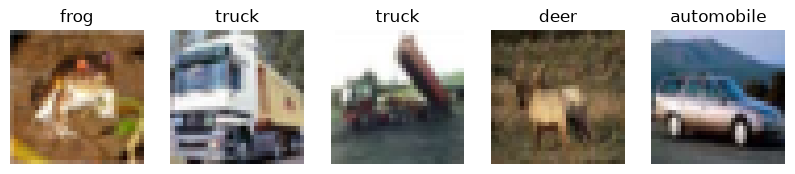

In [168]:
fig, axes = plt.subplots(1, 5, figsize=(10, 5))

for i, ax in enumerate(axes.flat):
    image, label = train_dataset[i]

    ax.imshow(image.permute(1, 2, 0))
    ax.set_title(train_dataset.classes[label])
    ax.axis("off")

plt.show()

Pre-processing steps:

- Convert images into tensors
- Use the CIFAR-10 training set for indexing
- Use the CIFAR-10 testing set for retrieval

# Feature Extraction

In [ ]:
import cv2
import numpy as np

sample_images = []

for i in range(5):
    image, label = train_dataset[i]

    image = image.permute(1, 2, 0).numpy()

    image = (image * 255).astype(np.uint8)

    sample_images.append(image)

sift = cv2.SIFT_create()


for i, image in enumerate(sample_images):

    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

    keypoints, descriptors = sift.detectAndCompute(gray, None)

    print("Image", i + 1)
    print("Keypoints:", len(keypoints))
    print("Descriptor shape:", descriptors.shape)
    print()

Image 1
Keypoints: 14
Descriptor shape: (14, 128)

Image 2
Keypoints: 21
Descriptor shape: (21, 128)

Image 3
Keypoints: 13
Descriptor shape: (13, 128)

Image 4
Keypoints: 13
Descriptor shape: (13, 128)

Image 5
Keypoints: 14
Descriptor shape: (14, 128)



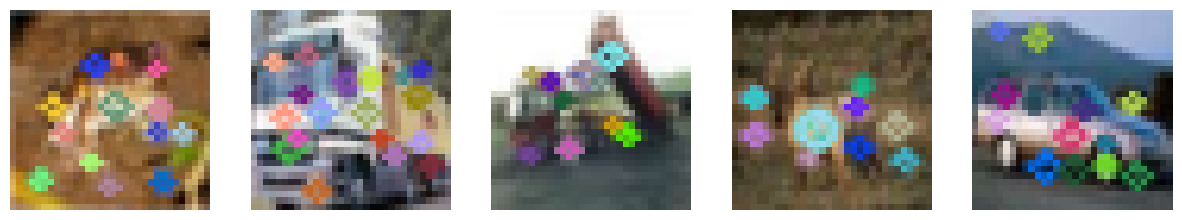

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(15, 4))

for i, image in enumerate(sample_images):
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

    keypoints, descriptors = sift.detectAndCompute(gray, None)

    output = cv2.drawKeypoints(image, keypoints, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

    axes[i].imshow(output)
    axes[i].axis("off")

plt.show()

SIFT achieves scale invariance by detecting keypoints at many scales.

It achieves rotation invariance by giving each keypoint a direction based on how the pixels around it change

In [ ]:
#Reference: https://www.kaggle.com/code/carloalbertobarbano/vgg16-transfer-learning-pytorch
import torch

vgg16 = models.vgg16(weights=models.VGG16_Weights.DEFAULT)

vgg16.eval()

resize = transforms.Resize((224, 224))

for i in range(3):
    image, label = train_dataset[i]

    image = resize(image)

    image = image.unsqueeze(0)

    with torch.no_grad():

        conv_features = vgg16.features(image)

        pooled_features = vgg16.avgpool(conv_features)
        flattened = torch.flatten(pooled_features, 1)
        fully_connected_features = vgg16.classifier(flattened)

    print("Image", i + 1)
    print("Convolutional:", conv_features.shape)
    print("Fully connected:", fully_connected_features.shape)
    print()

Image 1
Convolutional: torch.Size([1, 512, 7, 7])
Fully connected: torch.Size([1, 1000])

Image 2
Convolutional: torch.Size([1, 512, 7, 7])
Fully connected: torch.Size([1, 1000])

Image 3
Convolutional: torch.Size([1, 512, 7, 7])
Fully connected: torch.Size([1, 1000])



The last convolutional layer created a feature map with information such as shapes, textures and object locations

The final fully connected layer created a smaller, more abstract summary

For image retrieval, features from the last convolutional layer are more suitable because they keep more details, which helps identify similar images

# Similarity Measures


In [172]:
database_size = 300

resize = transforms.Resize((224, 224))

database_features = []
database_images = []

for i in range(database_size):
    image, label = train_dataset[i]
    database_images.append(image)
    image = resize(image).unsqueeze(0)

    with torch.no_grad():
        features = vgg16.features(image)
        features = vgg16.avgpool(features)
        features = torch.flatten(features)

    database_features.append(features.numpy())

In [ ]:
#Reference (please translate website to English to read): https://docs.pingcode.com/baike/1260759
def cosine_similarity(vector1, vector2):
    numerator = np.dot(vector1, vector2)
    denominator = np.linalg.norm(vector1) * np.linalg.norm(vector2)

    return numerator / denominator


def euclidean_distance(vector1, vector2):
    difference = vector1 - vector2

    return np.sqrt(np.sum(difference ** 2))

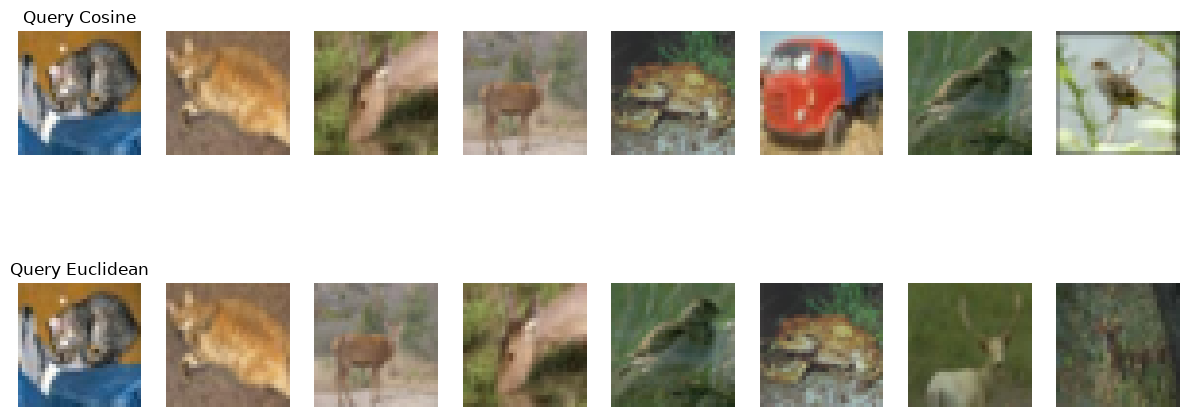

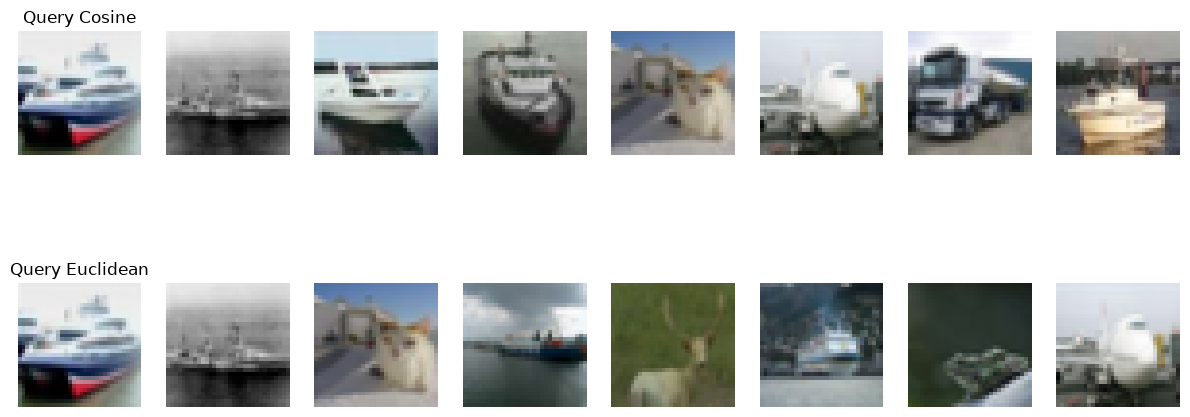

In [ ]:
k = 7

for query_number in range(2):
    query_image, label = test_dataset[query_number]

    image = resize(query_image).unsqueeze(0)

    with torch.no_grad():
        query_feature = vgg16.features(image)
        query_feature = vgg16.avgpool(query_feature)
        query_feature = torch.flatten(query_feature)

    query_feature = query_feature.numpy()

    cosine_scores = []
    euclidean_scores = []

    for feature in database_features:
        cosine_scores.append(
            cosine_similarity(query_feature, feature)
        )

        euclidean_scores.append(
            euclidean_distance(query_feature, feature)
        )

    cosine_indices = np.argsort(cosine_scores)[-k:][::-1]
    euclidean_indices = np.argsort(euclidean_scores)[:k]

    fig, axes = plt.subplots(2, k + 1, figsize=(15, 6))

    axes[0, 0].imshow(query_image.permute(1, 2, 0))
    axes[0, 0].set_title("Query Cosine") 
    axes[0, 0].axis("off")

    axes[1, 0].imshow(query_image.permute(1, 2, 0))
    axes[1, 0].set_title("Query Euclidean") 
    axes[1, 0].axis("off")



    for i, index in enumerate(cosine_indices):
        axes[0, i + 1].imshow(database_images[index].permute(1, 2, 0))
        axes[0, i + 1].axis("off")

    for i, index in enumerate(euclidean_indices):
        axes[1, i + 1].imshow(database_images[index].permute(1, 2, 0))
        axes[1, i + 1].axis("off")

    plt.show()

Cosine similarity tends to retrieve images that share a similar structure pattern or shape

Euclidean distance tends to retrieve images that share a similar overall color or brightness

The subject does not matter here since we see a mix of animals and objects in both metrics.

# Image Retrieval Pipeline


In [175]:
import numpy as np
import cv2
from sklearn.cluster import KMeans

def extract_sift_features(image):
    # Convert the image to grayscale
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Create a SIFT feature extractor
    sift = cv2.SIFT_create()

    # Detect and compute SIFT features
    keypoints, descriptors = sift.detectAndCompute(gray, None)
    # print("keypoint :",keypoints)
    # print("descriptors :",descriptors)

    return descriptors

def cluster_features(features, k):
    # Perform K-means clustering
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(features)

    # Get the cluster centers (visual words)
    visual_words = kmeans.cluster_centers_

    return visual_words

In [176]:
from collections import defaultdict

In [ ]:
database_size = 300

database_images = []

all_features = []

database_descriptors = []

for i in range(database_size):
    image, label = train_dataset[i]
    image = image.permute(1, 2, 0).numpy()
    image = (image * 255).astype(np.uint8)
    image = cv2.cvtColor(image, cv2.COLOR_RGB2BGR)

    database_images.append(image)

    descriptors = extract_sift_features(image)

    database_descriptors.append(descriptors)

    if descriptors is not None:
        all_features.extend(descriptors)


all_features = np.array(all_features)

print(all_features.shape)

(3936, 128)


In [ ]:
k = 50

visual_words = cluster_features(all_features, k)

print(visual_words.shape)

(50, 128)


In [ ]:
database_word_ids = []

for descriptors in database_descriptors:
    words = []

    if descriptors is not None:
        for descriptor in descriptors:
            distances = np.linalg.norm(visual_words - descriptor, axis=1)

            word_id = np.argmin(distances)
            words.append(word_id)

    database_word_ids.append(words)

In [ ]:
query_image, label = test_dataset[0]

query_image = query_image.permute(1, 2, 0).numpy()

query_image = (query_image * 255).astype(np.uint8)

query_image = cv2.cvtColor(query_image, cv2.COLOR_RGB2BGR)

query_descriptors = extract_sift_features(query_image)

print(query_descriptors.shape)

(10, 128)


In [ ]:
query_word_ids = []

for descriptor in query_descriptors:
    distances = np.linalg.norm(
        visual_words - descriptor,
        axis=1
    )

    word_id = np.argmin(distances)

    query_word_ids.append(word_id)

In [ ]:
inverted_index = defaultdict(list)

for image_id, words in enumerate(database_word_ids):
    for word in set(words):
        inverted_index[word].append(image_id)

In [ ]:
scores = {}

for word in query_word_ids:
    if word in inverted_index:
        for image_id in inverted_index[word]:
            if image_id not in scores:
                scores[image_id] = 0

            scores[image_id] += 1

top_k = 5

ranked_images = sorted(
    scores.items(),
    key=lambda x: x[1],
    reverse=True
)[:top_k]

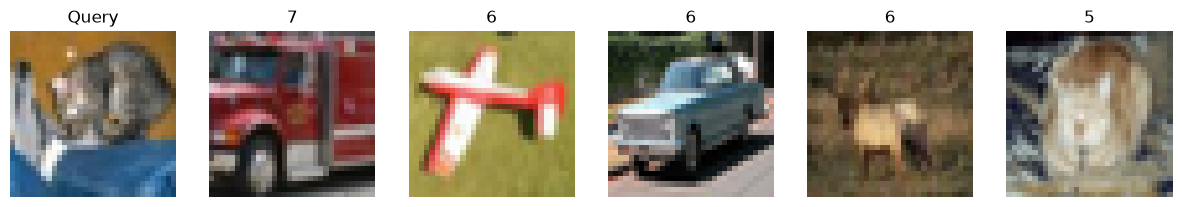

In [184]:
fig, axes = plt.subplots(1, top_k + 1, figsize=(15, 4))

axes[0].imshow(cv2.cvtColor(query_image, cv2.COLOR_BGR2RGB))

axes[0].set_title("Query")

axes[0].axis("off")

for i, (image_id, score) in enumerate(ranked_images):
    image = database_images[image_id]

    axes[i + 1].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    axes[i + 1].set_title(score)
    axes[i + 1].axis("off")

plt.show()

# Vector Database Integration

In [ ]:
# Reference: https://medium.com/@caring_smitten_gerbil_914/demystifying-nn-adaptiveavgpool2d-in-pytorch-why-adaptive-pooling-matters-in-deep-learning-1f7b7b1cc9b0
from pinecone import Pinecone, ServerlessSpec
import torch.nn as nn

pc = Pinecone(api_key="putyourAPIkeyhere")

index_name = "cifar10-index"

if index_name in pc.list_indexes().names():
    pc.delete_index(index_name)

pc.create_index(
    name=index_name,
    dimension=512,
    metric="cosine",
    spec=ServerlessSpec(cloud="aws", region="us-east-1")
)

index = pc.Index(index_name)

resize = transforms.Resize((224, 224))
avg_pool = nn.AdaptiveAvgPool2d((1, 1))

In [ ]:
vectors = []
database_size = 300

for i in range(database_size):
    image, label = train_dataset[i]
    image_input = resize(image).unsqueeze(0)

    with torch.no_grad():
        features = vgg16.features(image_input)
        features = avg_pool(features)
        features = torch.flatten(features)

    vectors.append((str(i), features.numpy().tolist(), {"label": int(label)}))

index.upsert(vectors=vectors, batch_size=100)

UpsertResponse(SUCCESS: 300/300 items, 3/3 batches)

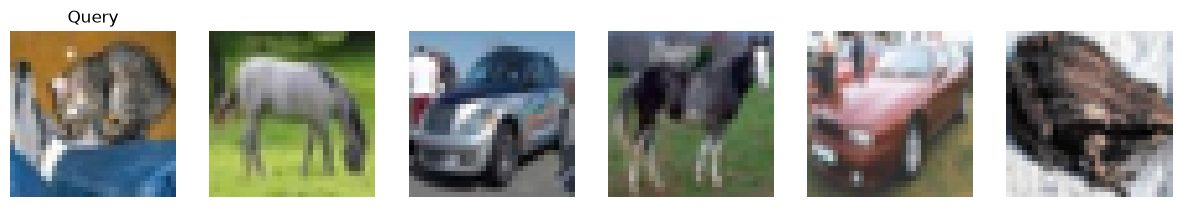

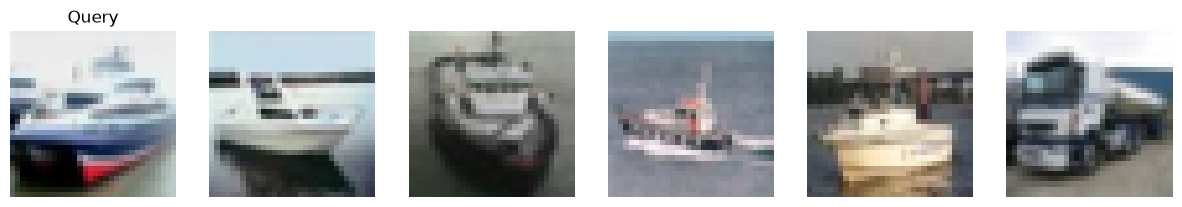

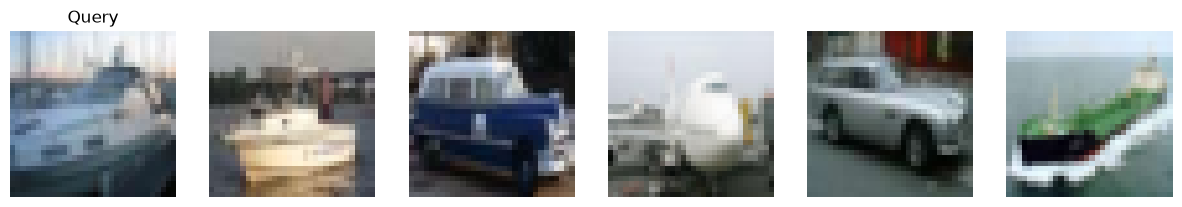

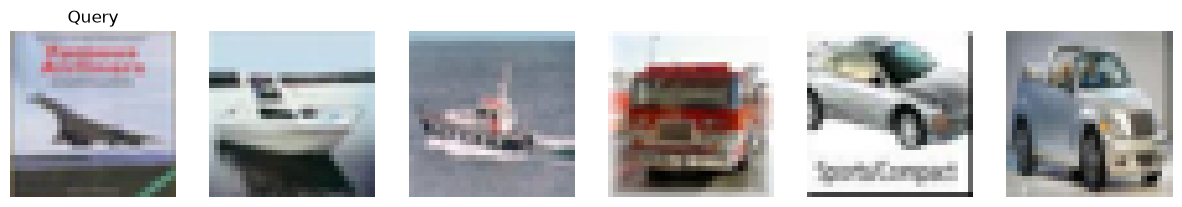

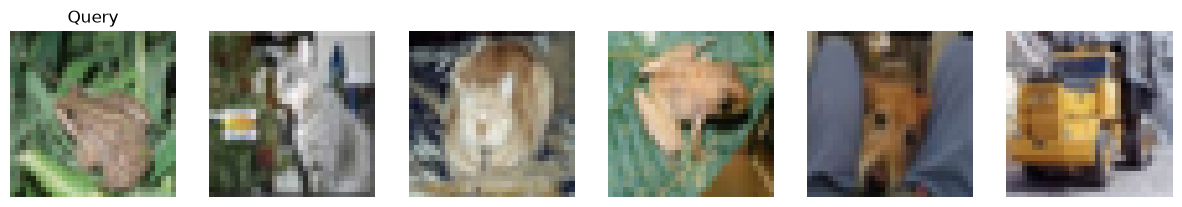

In [187]:
top_k = 5

for query_number in range(5):
    query_image, label = test_dataset[query_number]
    image_input = resize(query_image).unsqueeze(0)

    with torch.no_grad():
        query_feature = vgg16.features(image_input)
        query_feature = avg_pool(query_feature)
        query_feature = torch.flatten(query_feature)

    results = index.query(vector=query_feature.numpy().tolist(), top_k=top_k)

    fig, axes = plt.subplots(1, top_k + 1, figsize=(15, 4))
    axes[0].imshow(query_image.permute(1, 2, 0))
    axes[0].set_title("Query")
    axes[0].axis("off")

    for i, match in enumerate(results["matches"]):
        image_id = int(match["id"])
        image, label = train_dataset[image_id]
        axes[i + 1].imshow(image.permute(1, 2, 0))
        axes[i + 1].axis("off")

    plt.show()


In [ ]:
# Reference: https://www.geeksforgeeks.org/computer-vision/mean-average-precision-map-in-computer-vision/
APs = []
precision = np.zeros(5)
recall = np.zeros(5)

for i in range(5):
    query_image, true_label = test_dataset[i]
    image_input = resize(query_image).unsqueeze(0)

    with torch.no_grad():
        query_feature = vgg16.features(image_input)
        query_feature = avg_pool(query_feature)
        query_feature = torch.flatten(query_feature)

    results = index.query(vector=query_feature.numpy().tolist(), top_k=5)

    total_relevant = max(
        sum(1 for j in range(database_size) if train_dataset[j][1] == true_label), 1
    )

    relevant = 0
    precisions = []

    for rank, match in enumerate(results["matches"], start=1):
        img_id = int(match["id"])
        _, label = train_dataset[img_id]

        if label == true_label:
            relevant += 1
            precisions.append(relevant / rank)

        precision[rank - 1] += relevant / rank
        recall[rank - 1] += relevant / total_relevant

    APs.append(np.mean(precisions) if precisions else 0)

precision = precision/5
recall = recall/5

mAP = np.mean(APs)
print("mAP:", mAP)

mAP: 0.4066666666666666


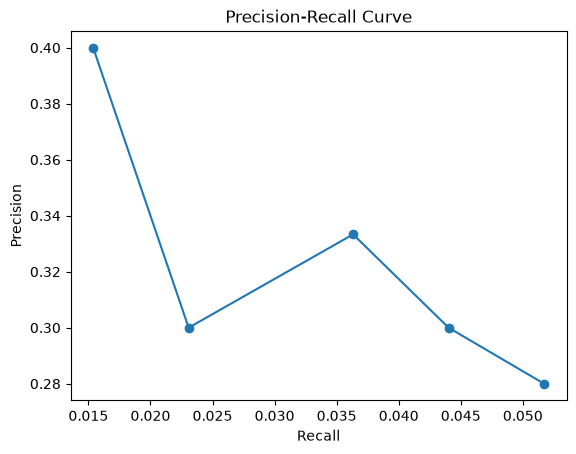

In [189]:
plt.plot(recall, precision, marker='o')
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.show()

Failure cases occur when different images have similar features.

For example, ships and airplanes may both contain blue backgrounds because of the sky. This might cause incorrect retrieval. Low-resolution CIFAR-10 images also remove details that differentiate one object to another.

To improve the robustness and efficiency of the retrieval system, we can use a larger dataset, or use more test images, and increase the number of indexed images.
